# Assignment 1 — Question 4 only

No fine-tuning. No evaluation. Analyze the original Llama-3.2-1B.

Inputs this notebook needs:
1. Kaggle secret `HF_TOKEN` (same as the training notebook).
2. Internet on, so it can download `meta-llama/Llama-3.2-1B` if not cached.
3. No training data, no GSM8K, no MATH.

Outputs:
- `q4_min_rank.csv` — min rank for 50% cumulative energy, layers 0 / 7 / 15.
- `q4_singular_values.csv` — singular values used for the plots.
- 6 PNG figures under `/kaggle/working/Assignment1_Q4/`.


In [1]:
import gc
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM

SEED = 42
torch.manual_seed(SEED)

MODEL_ID = 'meta-llama/Llama-3.2-1B'
MODEL_DTYPE = torch.float16
LAYERS = [0, 7, 15]
ENERGY_THRESHOLD = 0.50
PLOT_FIRST_N = 200

RESULT_ROOT = Path('/kaggle/working/Assignment1_Q4')
RESULT_ROOT.mkdir(parents=True, exist_ok=True)

print('PyTorch:', torch.__version__)
print('CUDA:', torch.cuda.is_available(), 'GPU count:', torch.cuda.device_count())
print('Results:', RESULT_ROOT)


PyTorch: 2.11.0+cu128
CUDA: True GPU count: 2
Results: /kaggle/working/Assignment1_Q4


In [2]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

try:
    token = UserSecretsClient().get_secret('HF_TOKEN')
    login(token=token)
    print('Hugging Face login: OK')
except Exception as exc:
    print('HF login was not completed automatically:', exc)
    print('If the model is already cached and accessible, you can continue.')


Hugging Face login: OK


In [3]:
print('Loading original model on CPU...')
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=MODEL_DTYPE,
    device_map='cpu',
    low_cpu_mem_usage=True,
)
model.eval()
print('Loaded. Layers:', model.config.num_hidden_layers)
print('Hidden size:', model.config.hidden_size)


Loading original model on CPU...


config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

Loaded. Layers: 16
Hidden size: 2048


In [4]:
def get_q_proj(model, layer_idx):
    layer = model.model.layers[layer_idx]
    linear = layer.self_attn.q_proj
    name = f'model.layers.{layer_idx}.self_attn.q_proj'
    return name, linear

for idx in LAYERS:
    name, linear = get_q_proj(model, idx)
    print(name, tuple(linear.weight.shape), linear.weight.dtype)


model.layers.0.self_attn.q_proj (2048, 2048) torch.float16
model.layers.7.self_attn.q_proj (2048, 2048) torch.float16
model.layers.15.self_attn.q_proj (2048, 2048) torch.float16


In [5]:
@torch.no_grad()
def svd_q_proj(model, layer_idx):
    name, linear = get_q_proj(model, layer_idx)
    W = linear.weight.detach().float().cpu()
    # Full SVD, economy form. S is already descending.
    U, S, Vh = torch.linalg.svd(W, full_matrices=False)
    S = S.numpy()
    energy = S ** 2
    total = float(energy.sum())
    cumulative = np.cumsum(energy) / total
    # First k whose cumulative energy is at least 50%.
    min_rank = int(np.searchsorted(cumulative, ENERGY_THRESHOLD, side='left') + 1)
    print(
        f'{name}: shape={tuple(W.shape)} singular_values={len(S)} '
        f'total_energy={total:.4f} min_rank_50={min_rank} '
        f'cum_at_min={cumulative[min_rank-1]:.4f}'
    )
    del U, Vh, W
    gc.collect()
    return {
        'layer': layer_idx,
        'module': name,
        'weight_shape': str(tuple(linear.weight.shape)),
        'num_singular_values': int(len(S)),
        'total_energy': total,
        'min_rank_50': min_rank,
        'cumulative_at_min_rank': float(cumulative[min_rank - 1]),
        'S': S,
        'cumulative': cumulative,
    }

results = [svd_q_proj(model, idx) for idx in LAYERS]


model.layers.0.self_attn.q_proj: shape=(2048, 2048) singular_values=2048 total_energy=5703.2627 min_rank_50=62 cum_at_min=0.5017
model.layers.7.self_attn.q_proj: shape=(2048, 2048) singular_values=2048 total_energy=2917.9314 min_rank_50=120 cum_at_min=0.5020
model.layers.15.self_attn.q_proj: shape=(2048, 2048) singular_values=2048 total_energy=2607.1099 min_rank_50=84 cum_at_min=0.5012


In [6]:
table = pd.DataFrame([
    {
        'layer': r['layer'],
        'module': r['module'],
        'weight_shape': r['weight_shape'],
        'num_singular_values': r['num_singular_values'],
        'total_energy': r['total_energy'],
        'min_rank_50': r['min_rank_50'],
        'cumulative_at_min_rank': r['cumulative_at_min_rank'],
    }
    for r in results
])
table_path = RESULT_ROOT / 'q4_min_rank.csv'
table.to_csv(table_path, index=False)
print(table.to_string(index=False))
print('Saved:', table_path)


 layer                           module weight_shape  num_singular_values  total_energy  min_rank_50  cumulative_at_min_rank
     0  model.layers.0.self_attn.q_proj (2048, 2048)                 2048   5703.262695           62                0.501701
     7  model.layers.7.self_attn.q_proj (2048, 2048)                 2048   2917.931396          120                0.502010
    15 model.layers.15.self_attn.q_proj (2048, 2048)                 2048   2607.109863           84                0.501154
Saved: /kaggle/working/Assignment1_Q4/q4_min_rank.csv


In [7]:
rows = []
for r in results:
    n = min(PLOT_FIRST_N, len(r['S']))
    for i in range(n):
        rows.append({
            'layer': r['layer'],
            'index': i + 1,
            'singular_value': float(r['S'][i]),
            'cumulative_energy': float(r['cumulative'][i]),
        })
sv_df = pd.DataFrame(rows)
sv_path = RESULT_ROOT / 'q4_singular_values.csv'
sv_df.to_csv(sv_path, index=False)
print('Saved:', sv_path, 'rows:', len(sv_df))


Saved: /kaggle/working/Assignment1_Q4/q4_singular_values.csv rows: 600


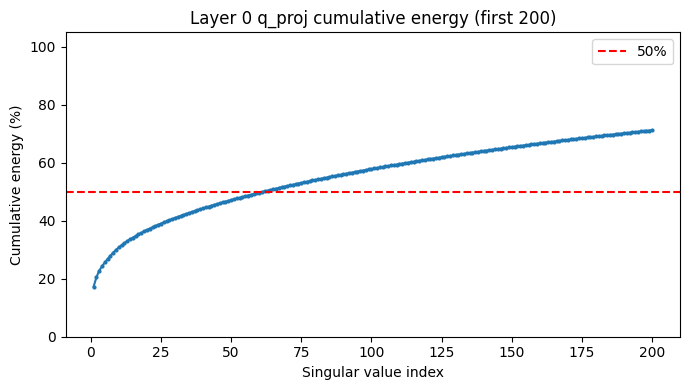

Saved: /kaggle/working/Assignment1_Q4/q4_layer0_cumulative_energy.png


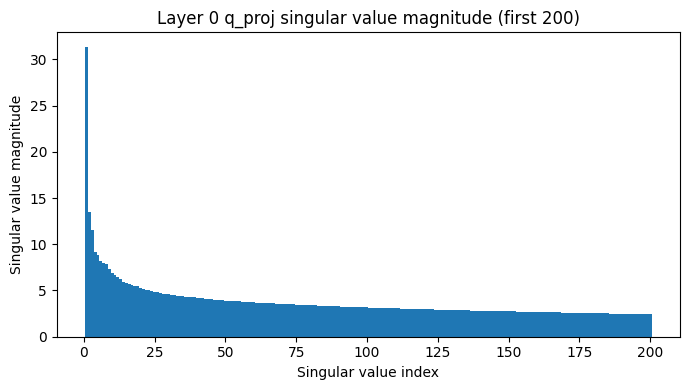

Saved: /kaggle/working/Assignment1_Q4/q4_layer0_singular_values.png


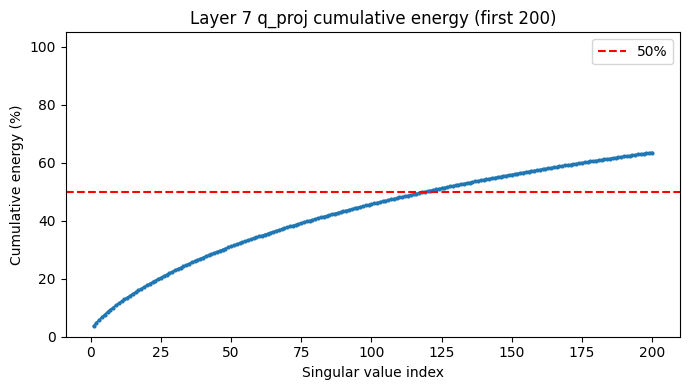

Saved: /kaggle/working/Assignment1_Q4/q4_layer7_cumulative_energy.png


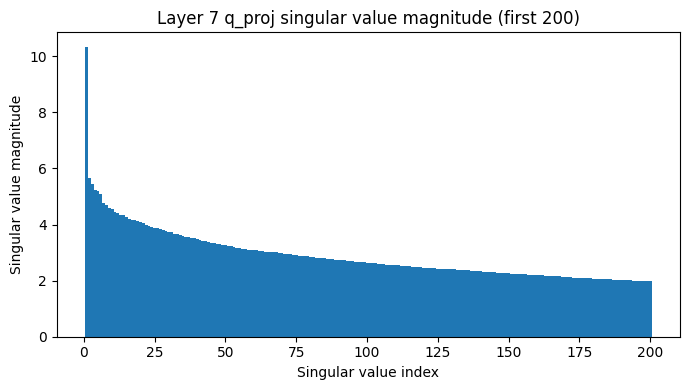

Saved: /kaggle/working/Assignment1_Q4/q4_layer7_singular_values.png


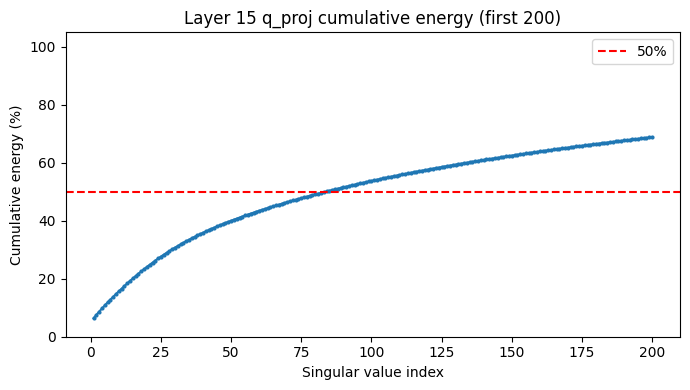

Saved: /kaggle/working/Assignment1_Q4/q4_layer15_cumulative_energy.png


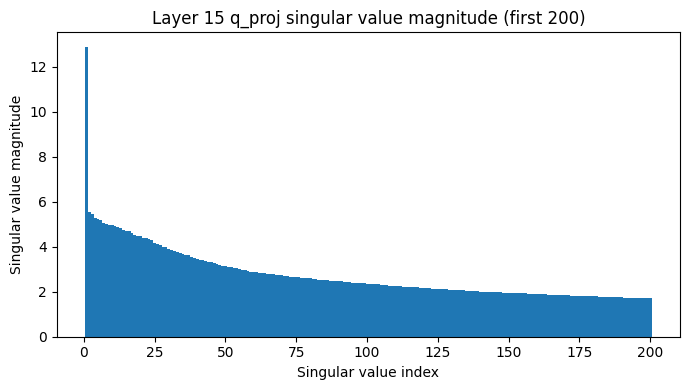

Saved: /kaggle/working/Assignment1_Q4/q4_layer15_singular_values.png


In [8]:
for r in results:
    n = min(PLOT_FIRST_N, len(r['S']))
    idx = np.arange(1, n + 1)
    layer = r['layer']

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(idx, r['cumulative'][:n] * 100, marker='o', markersize=2)
    ax.axhline(ENERGY_THRESHOLD * 100, color='red', linestyle='--', label='50%')
    ax.set_title(f'Layer {layer} q_proj cumulative energy (first {n})')
    ax.set_xlabel('Singular value index')
    ax.set_ylabel('Cumulative energy (%)')
    ax.set_ylim(0, 105)
    ax.legend()
    fig.tight_layout()
    line_path = RESULT_ROOT / f'q4_layer{layer}_cumulative_energy.png'
    fig.savefig(line_path, dpi=150)
    plt.show()
    print('Saved:', line_path)

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(idx, r['S'][:n], width=1.0)
    ax.set_title(f'Layer {layer} q_proj singular value magnitude (first {n})')
    ax.set_xlabel('Singular value index')
    ax.set_ylabel('Singular value magnitude')
    fig.tight_layout()
    bar_path = RESULT_ROOT / f'q4_layer{layer}_singular_values.png'
    fig.savefig(bar_path, dpi=150)
    plt.show()
    print('Saved:', bar_path)


In [9]:
del model
gc.collect()
print('Done. Files:')
for p in sorted(RESULT_ROOT.iterdir()):
    print(' ', p.name)


Done. Files:
  q4_layer0_cumulative_energy.png
  q4_layer0_singular_values.png
  q4_layer15_cumulative_energy.png
  q4_layer15_singular_values.png
  q4_layer7_cumulative_energy.png
  q4_layer7_singular_values.png
  q4_min_rank.csv
  q4_singular_values.csv
